# Trabalho 2 — Projeto final: internações respiratórias e qualidade do ar
**Redes Neurais e Aprendizado Profundo (EMA9824) · 2026/2** · Grupo: Lucas Silveira, Nívea Batoni, Renan Cazelotto · Repositório: <https://github.com/LucasSilveira30/T2-Redes-Neurais>

**Pergunta (proposta, seção 1):** incluir poluentes do ar (MP10, MP2,5, NO₂, O₃) reduz o erro de previsão das internações diárias por doenças respiratórias, em relação a um baseline sazonal e à mesma rede sem poluentes? Municípios: Piracicaba e São Paulo (capital). Métrica: **MAE**. Horizontes: 1, 7 e 14 dias.

**O que este notebook faz, de ponta a ponta**
1. Obtém os dados (`dados_t2.zip`, baixado do repositório se ainda não estiver no ambiente) e documenta a cobertura de cada variável.
2. Aplica **um único pré-processamento** a todos os modelos (mesma divisão, mesma métrica).
3. Mede os baselines da proposta: **média sazonal** com tendência e **regressão de Poisson** sem e com poluentes.
4. Treina o **GRU** (janela de 28 dias) **sem** e **com** poluentes, com **3 sementes** por configuração, checkpoints e parada antecipada. Temperatura, umidade e calendário entram nas duas versões: os poluentes são o único fator variado.
5. Mostra os resultados na **validação (2018)**; só depois, **uma única vez**, avalia tudo no **teste (2019)**.
6. Aplica o **critério de empate** da proposta (seção 7) e gera as figuras e tabelas do artigo.

**Regras do projeto que o notebook respeita**
- Divisão pela data do **alvo**: treino 2014–2017, validação 2018, teste 2019. 2020–2021 ficam fora (os arquivos terminam em 2019).
- **O teste só é lido na seção 6.** Até lá, os dados são cortados em 31/12/2018 e nada é decidido com o teste. Hiperparâmetros, parada antecipada e escolha do `alpha` do Poisson usam só a validação.
- Todo parâmetro estimado (preenchimento de lacunas, padronização, fatores sazonais, pesos) usa **somente o treino**.
- Um fator por vez: as duas versões de cada modelo diferem **apenas** nos poluentes.

**Como executar no Google Colab:** `Ambiente de execução → Executar tudo`. Não precisa de GPU (o notebook roda em CPU de propósito). O tempo total aparece na última célula. Se a sessão cair no meio do treino do GRU, rode de novo: os checkpoints em `checkpoints_gru/` retomam do último ponto (para que sobrevivam a uma sessão nova, aponte `PASTA_CKPT` para o Drive).

In [ ]:
# ============================== 1. Configuração ==============================
import os, sys, glob, time, json, hashlib, zipfile, platform, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from dateutil.easter import easter
from scipy.stats import poisson
from sklearn.linear_model import PoissonRegressor        # só na verificação de sanidade do Poisson
from IPython.display import display

T0 = time.perf_counter()                                  # cronômetro (reiniciado depois de obter os dados)
SEMENTE = 42                                              # semente global
SEMENTES_GRU = [42, 43, 44]                               # 3 sementes por configuração de GRU
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
torch.set_num_threads(max(1, os.cpu_count() or 1))        # tudo roda em CPU (nenhum tensor vai para GPU)
warnings.filterwarnings('ignore', category=UserWarning, module='torch')

# --- Divisão temporal (sempre pela data do ALVO) ---
FIM_TREINO = '2017-12-31'                                 # treino: 2014–2017
INI_VAL, FIM_VAL = '2018-01-01', '2018-12-31'             # validação: 2018
INI_TESTE, FIM_TESTE = '2019-01-01', '2019-12-31'         # teste: 2019 (só é lido na seção 6, uma única vez)

HORIZONTES = [1, 7, 14]                                   # dias à frente
MUNICIPIOS = {                                            # município -> (arquivo de internações, arquivo de qualidade do ar)
    'Piracicaba': ('internacoes_respiratorias-Piracicaba.csv', 'diario_municipio_Piracicaba.csv'),
    'São Paulo':  ('internacoes_respiratorias-Sao_Paulo.csv',  'diario_municipio_Sao_Paulo.csv'),
}
POLUENTES = ['mp10', 'mp25', 'no2', 'o3']
METEO     = ['temp', 'ur']                                # entram nas DUAS versões (sem e com poluentes)

# --- Pré-processamento (igual ao M2) ---
LIMITE_FFILL  = 3         # preenche lacunas de até 3 dias com o último valor (só usa o passado)
COBERTURA_MIN = 0.5       # variável só entra se tiver >= 50% de dias com medição NO TREINO

# --- Atributos tabulares do Poisson (todos construídos só com dias <= origem t) ---
LAGS_CONTAGEM   = 7       # contagens em t, t-1, ..., t-6
JANELA_CONTAGEM = 28      # média das contagens nos últimos 28 dias
LAGS_EXOG       = [0, 1, 2, 3]   # poluentes e meteorologia em t, t-1, t-2, t-3 ...
JANELA_EXOG     = 7              # ... mais a média dos últimos 7 dias
K_FOURIER       = 3       # harmônicos anuais no calendário

# --- Baselines (iguais ao M2) ---
SUAVIZAR_SEMANAS = 3                       # suavização circular (em semanas) dos fatores sazonais
ALPHAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]     # penalidade L2 do Poisson (escolhida pelo MAE na validação)
GLM_LR, GLM_MAX_EPOCAS, GLM_TOL, GLM_PACIENCIA = 0.01, 5000, 1e-10, 100

# --- GRU (HIDDEN e GRU_LR fixados com a validação, ver seção 4; iguais para as duas versões e todos os municípios) ---
JANELA = 28               # dias de histórico na entrada
HIDDEN, DROPOUT = 64, 0.1
GRU_LR, GRU_WD, BATCH, CLIP = 3e-3, 1e-4, 64, 1.0
GRU_MAX_EPOCAS, GRU_PACIENCIA = 150, 15    # parada antecipada: 15 épocas sem melhora na validação
PASTA_CKPT, RETOMAR = 'checkpoints_gru', True

# --- Critério de empate (proposta, seção 7) ---
LIMIAR_DP = 2.0           # "por mais de 2 desvios-padrão entre sementes"

NOME_SAZ, NOME_P_SEM, NOME_P_COM = 'Média sazonal', 'Poisson sem poluentes', 'Poisson com poluentes'
NOME_G_SEM, NOME_G_COM = 'GRU sem poluentes', 'GRU com poluentes'
ORDEM_MODELOS = [NOME_SAZ, NOME_P_SEM, NOME_P_COM, NOME_G_SEM, NOME_G_COM]
try:
    import google.colab
    NO_COLAB = True
except ImportError:
    NO_COLAB = False
AMBIENTE = 'Google Colab (CPU)' if NO_COLAB else 'ambiente local (CPU)'

print(f'Ambiente : {AMBIENTE} | {os.cpu_count()} CPU(s) | Python {platform.python_version()}')
print(f'Pacotes  : numpy {np.__version__} | pandas {pd.__version__} | scipy {__import__("scipy").__version__} | '
      f'scikit-learn {__import__("sklearn").__version__} | matplotlib {plt.matplotlib.__version__} | torch {torch.__version__}')
print(f'Sementes : global {SEMENTE} | GRU {SEMENTES_GRU} | Poisson e média sazonal são determinísticos')
print(f'Teste (2019) fechado até a seção 6.')

Ambiente : Google Colab (CPU) | 2 CPU(s) | Python 3.13.18
Pacotes  : numpy 2.4.6 | pandas 2.2.3 | scipy 1.16.3 | scikit-learn 1.6.1 | matplotlib 3.10.0 | torch 2.14.1+cpu
Sementes : global 42 | GRU [42, 43, 44] | Poisson e média sazonal são determinísticos
Teste (2019) fechado até a seção 6.


## 2. Dados
O notebook usa o `dados_t2.zip` do repositório: 4 CSVs agregados (contagens diárias e valores diários por município), sem dados individuais. A coleta a partir das fontes originais (SIH/SUS e QUALAR/CETESB) está nos scripts de `extracao_dados_brutos/` e descrita no README do repositório. Os brutos são grandes e não ficam no git.

- `internacoes_respiratorias-<Município>.csv`: internações com diagnóstico principal no capítulo J da CID-10, por data de internação e município de residência (SIH/SUS).
- `diario_municipio_<Município>.csv`: valor diário de cada variável, **médias entre as estações do município**. O valor diário por estação segue as regras do portal: média para MP10 e MP2,5; máxima horária para NO₂; máxima da média móvel de 8 h para O₃; máxima para temperatura e mínima para umidade. O dia só vale com pelo menos 18 horas válidas. `nest_*` é o número de estações que contribuíram e `n_*` vale 24 quando há valor e 0 quando não há.

In [ ]:
# ---------------- Obtém os arquivos (o caminho do zip é livre) ----------------
CAMINHO_ZIP = 'dados_t2.zip'        # <- caminho do zip, em qualquer pasta (ex.: '/content/drive/MyDrive/<pasta>/dados_t2.zip')
URL_ZIP = 'https://github.com/LucasSilveira30/T2-Redes-Neurais/raw/main/dados_t2.zip'   # usado se o zip não for achado
DESTINO = 'dados_extraidos'         # pasta local (descartada com a sessão) onde o zip é extraído
ARQ_MARCADOR = next(iter(MUNICIPIOS.values()))[0]   # um dos CSVs, usado para achar a pasta certa dentro do zip

def localizar_pasta():
    achados = glob.glob(os.path.join(DESTINO, '**', ARQ_MARCADOR), recursive=True)
    return os.path.dirname(achados[0]) if achados else None

def montar_drive_se_preciso(caminho):
    if not os.path.abspath(os.path.expanduser(caminho)).startswith('/content/drive'):
        return                                                    # o caminho não está no Drive
    try:
        from google.colab import drive
        drive.mount('/content/drive')                             # o Colab pede autorização na primeira vez
    except Exception as erro:
        print('Não consegui montar o Drive:', erro)

PASTA = localizar_pasta()
if PASTA is None:
    CAMINHO_ZIP = os.path.expanduser(CAMINHO_ZIP)
    montar_drive_se_preciso(CAMINHO_ZIP)
    if not os.path.exists(CAMINHO_ZIP):                           # 2ª opção: baixar do repositório
        try:
            print(f'{CAMINHO_ZIP} não encontrado; baixando do repositório do GitHub ...')
            destino_zip = os.path.basename(CAMINHO_ZIP) or 'dados_t2.zip'
            urllib.request.urlretrieve(URL_ZIP, destino_zip)
            assert zipfile.is_zipfile(destino_zip), 'o arquivo baixado não é um zip'
            CAMINHO_ZIP = destino_zip
        except Exception as erro:
            print('Download falhou:', erro)
    if not os.path.exists(CAMINHO_ZIP):                           # último recurso: upload manual no Colab
        try:
            from google.colab import files
            print('Selecione o arquivo dados_t2.zip ...')
            CAMINHO_ZIP = list(files.upload().keys())[0]
        except ImportError:
            raise FileNotFoundError(f'Arquivo não encontrado: {CAMINHO_ZIP}. Ajuste CAMINHO_ZIP.')
    with zipfile.ZipFile(CAMINHO_ZIP) as z:
        z.extractall(DESTINO)
    PASTA = localizar_pasta()
else:
    print(f'Dados já extraídos em {DESTINO}/ (para reextrair, apague a pasta ou reinicie o ambiente).')

assert PASTA is not None, f'{ARQ_MARCADOR} não encontrado dentro do zip.'
for arq_int, arq_ex in MUNICIPIOS.values():
    for arq in (arq_int, arq_ex):
        assert os.path.exists(os.path.join(PASTA, arq)), f'Arquivo ausente: {arq}'
print('Pasta de dados:', os.path.abspath(PASTA))

dados_t2.zip não encontrado; baixando do repositório do GitHub ...
Pasta de dados: /content/dados_extraidos/dados_t2


In [ ]:
# ---------------- Leitura e diagnóstico (só treino + validação) ----------------
T0 = time.perf_counter()     # o tempo de execução conta daqui em diante (sem a montagem do Drive / download)

def ler_contagem(municipio, ultimo_dia):
    arq_int = MUNICIPIOS[municipio][0]
    d = pd.read_csv(os.path.join(PASTA, arq_int), encoding='utf-8-sig', parse_dates=['DT_INTER'])
    assert (d['MUNICIPIO'].str.strip() == municipio).all(), f'{arq_int}: o arquivo não é só de {municipio}'
    s = d.set_index('DT_INTER')['INTERNACOES'].sort_index().loc[:ultimo_dia]
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='D'))
    assert s.notna().all(), f'{municipio}: há dias sem contagem'
    return s.astype(float)

def ler_exogenas(municipio, ultimo_dia):
    d = (pd.read_csv(os.path.join(PASTA, MUNICIPIOS[municipio][1]), parse_dates=['data']).set_index('data').sort_index()
           .loc[:ultimo_dia])
    for v in POLUENTES + METEO:       # a regra das 18 horas válidas já foi aplicada em processar_qualar.py
        assert (d[v].notna() == (d['n_' + v] > 0)).all(), f'{municipio}/{v}: n_{v} inconsistente com o valor'
    estacoes = d[['nest_' + v for v in POLUENTES + METEO]].rename(columns=lambda c: c[5:])
    return d[POLUENTES + METEO], estacoes

# --- Internações: resumo por município e ano ---
resumo = []
for m in MUNICIPIOS:
    s = ler_contagem(m, FIM_VAL)
    g = s.groupby(s.index.year)
    resumo.append(pd.DataFrame({'municipio': m, 'ano': g.size().index, 'dias': g.size().values,
                                'total': g.sum().values, 'media_dia': g.mean().round(2).values,
                                'dp_dia': g.std().round(2).values,
                                'variancia/media': (g.var() / g.mean()).round(1).values,
                                'pct_dias_zero': (g.apply(lambda x: (x == 0).mean()) * 100).round(1).values}))
print('Internações respiratórias por dia (treino + validação). "variancia/media" = 1 seria Poisson puro:')
display(pd.concat(resumo, ignore_index=True))

# --- Poluentes e meteorologia: cobertura por ano e número de estações ---
for m in MUNICIPIOS:
    ex, estacoes = ler_exogenas(m, FIM_VAL)
    print(f'\n{m}: medições de {ex.index.min().date()} a {ex.index.max().date()}')
    print('Fração de dias com valor, por ano:')
    display(ex.notna().groupby(ex.index.year).mean().T.round(2))
    print('Número médio de estações por dia:')
    display(estacoes.groupby(estacoes.index.year).mean().T.round(1))

Internações respiratórias por dia (treino + validação). "variancia/media" = 1 seria Poisson puro:


,municipio,ano,dias,total,media_dia,dp_dia,variancia/media,pct_dias_zero
0,Piracicaba,2014,365,1909.0,5.23,3.33,2.1,2.7
1,Piracicaba,2015,365,2126.0,5.82,3.73,2.4,2.7
2,Piracicaba,2016,366,1864.0,5.09,2.86,1.6,3.0
3,Piracicaba,2017,365,1584.0,4.34,2.59,1.6,3.3
4,Piracicaba,2018,365,1864.0,5.11,2.80,1.5,2.2
5,São Paulo,2014,365,52844.0,144.78,43.53,13.1,0.0
6,São Paulo,2015,365,52290.0,143.26,42.89,12.8,0.0
7,São Paulo,2016,366,56618.0,154.69,51.93,17.4,0.0
8,São Paulo,2017,365,54230.0,148.58,40.75,11.2,0.0
9,São Paulo,2018,365,54272.0,148.69,43.53,12.7,0.0



Piracicaba: medições de 2014-01-01 a 2018-12-31
Fração de dias com valor, por ano:


data,2014,2015,2016,2017,2018
mp10,0.97,0.99,0.96,0.76,0.88
mp25,0.93,0.99,0.92,0.85,0.91
no2,0.95,0.58,0.90,0.84,0.84
o3,0.90,0.90,0.93,0.90,0.90
temp,0.90,0.92,0.76,0.81,0.34
ur,0.97,0.97,0.93,0.36,0.21


Número médio de estações por dia:


data,2014,2015,2016,2017,2018
mp10,1.0,1.0,1.0,0.8,0.9
mp25,0.9,1.0,0.9,0.8,0.9
no2,1.0,0.6,0.9,0.8,0.8
o3,0.9,0.9,0.9,0.9,0.9
temp,0.9,0.9,0.8,0.8,0.3
ur,1.0,1.0,0.9,0.4,0.2



São Paulo: medições de 2014-01-01 a 2018-12-31
Fração de dias com valor, por ano:


data,2014,2015,2016,2017,2018
mp10,1.0,1.0,1.0,1.0,1.0
mp25,1.0,1.0,1.0,1.0,1.0
no2,1.0,1.0,1.0,1.0,1.0
o3,1.0,1.0,1.0,1.0,1.0
temp,1.0,1.0,1.0,1.0,1.0
ur,1.0,1.0,1.0,1.0,1.0


Número médio de estações por dia:


data,2014,2015,2016,2017,2018
mp10,9.2,9.2,9.4,9.2,9.6
mp25,4.3,4.5,4.6,4.7,4.7
no2,7.9,8.2,8.3,7.9,8.3
o3,9.2,9.1,9.4,9.0,9.1
temp,2.8,2.9,2.9,2.9,2.9
ur,2.9,2.9,2.9,2.9,2.9


### Decisões de pré-processamento (as mesmas do M2)
- **Variáveis com cobertura baixa saem.** Uma variável só entra para um município se tiver ≥ 50% de dias medidos **no treino**; a decisão usa só o treino.
- **Lacunas.** Lacunas de até `LIMITE_FFILL` dias são preenchidas com o último valor (só passado); o restante, com a média **do mês** calculada no treino. O percentual de dias preenchidos em cada período é impresso abaixo.
- **Padronização.** Média e desvio de cada atributo vêm do treino.
- **Escalas diferentes.** São Paulo tem cerca de 150 internações por dia e Piracicaba, cerca de 5: o MAE absoluto não é comparável entre municípios, por isso as tabelas trazem também o MAE relativo (% da média diária). Em São Paulo as contagens são muito mais dispersas que um Poisson puro; o Poisson (e a perda de Poisson do GRU) continuam estimando a média, mas não servem para intervalos de confiança.

In [ ]:
# ---------------- Funções de pré-processamento ----------------
def feriados_nacionais(anos):
    fer = set()
    for a in anos:
        for mes, dia in [(1, 1), (4, 21), (5, 1), (9, 7), (10, 12), (11, 2), (11, 15), (12, 25)]:
            fer.add(pd.Timestamp(a, mes, dia))
        pascoa = pd.Timestamp(easter(a))
        for desloc in (-48, -47, -2, 60):                      # carnaval (seg/ter), sexta-feira santa, Corpus Christi
            fer.add(pascoa + pd.Timedelta(days=desloc))
    return fer

def calendario(idx):
    # atributos de um dia (conhecidos com antecedência, não vazam nada)
    cal = pd.DataFrame(index=idx)
    for d in range(1, 7):                                       # segunda = referência
        cal[f'dow{d}'] = (idx.dayofweek == d).astype(float)
    doy = idx.dayofyear.to_numpy()
    for k in range(1, K_FOURIER + 1):
        cal[f'sin{k}'] = np.sin(2 * np.pi * k * doy / 365.25)
        cal[f'cos{k}'] = np.cos(2 * np.pi * k * doy / 365.25)
    cal['feriado'] = idx.isin(list(feriados_nacionais(sorted(set(idx.year))))).astype(float)
    return cal

def preparar_municipio(m, ultimo_dia):
    # Tudo o que é estimado (variáveis usadas, médias de preenchimento, padronização) vem só do treino.
    y = ler_contagem(m, ultimo_dia)
    ex, _ = ler_exogenas(m, ultimo_dia)
    ini = ex.index.min()
    cobertura_treino = ex.loc[ini:FIM_TREINO].notna().mean()
    usar = [v for v in POLUENTES + METEO if cobertura_treino[v] >= COBERTURA_MIN]
    descartadas = [v for v in POLUENTES + METEO if v not in usar]

    obs = ex.loc[ini:, usar]                                    # observado (NaN = sem medição válida)
    obs_treino = obs.loc[:FIM_TREINO]
    x = obs.ffill(limit=LIMITE_FFILL)                           # só olha para trás
    clim = obs_treino.groupby(obs_treino.index.month).mean()    # média por mês, SÓ do treino
    for v in usar:
        padrao = pd.Series(clim[v].reindex(x.index.month).to_numpy(), index=x.index).fillna(obs_treino[v].mean())
        x[v] = x[v].fillna(padrao)
    z = (x - obs_treino.mean()) / obs_treino.std()              # padroniza com o treino
    assert not z.isna().any().any()
    return dict(y=y, z=z, obs=obs, ini=ini, pol=[v for v in usar if v in POLUENTES],
                met=[v for v in usar if v in METEO], descartadas=descartadas, cobertura_treino=cobertura_treino)

def montar_features(y, z, pol, met, h):
    # Atributos tabulares (Poisson). Linha indexada pelo dia-alvo d = t + h; todos os atributos usam só dias <= t.
    ly = np.log1p(y)
    F = {}
    for k in range(LAGS_CONTAGEM):
        F[f'cont_lag{k}'] = ly.shift(k)
    F['cont_media28'] = np.log1p(y.rolling(JANELA_CONTAGEM).mean())
    for v in met + pol:
        s = z[v].reindex(y.index)
        for k in LAGS_EXOG:
            F[f'{v}_lag{k}'] = s.shift(k)
        F[f'{v}_media{JANELA_EXOG}'] = s.rolling(JANELA_EXOG).mean()
    F = pd.DataFrame(F, index=y.index)
    F.index = F.index + pd.Timedelta(days=h)                    # origem t -> alvo t + h
    F = pd.concat([F, calendario(F.index)], axis=1)
    F['y'] = y.reindex(F.index)                                 # contagem do dia-alvo
    return F.dropna()

def colunas_modelo(F, pol):
    com = [c for c in F.columns if c != 'y']
    sem = [c for c in com if not any(c.startswith(p + '_') for p in pol)]
    return sem, com

def checar_sem_vazamento(F, y, z, h, pol, met, ultimo_dia, n=5):
    rng = np.random.default_rng(SEMENTE)
    um_dia = pd.Timedelta(days=1)
    for d in F.index[rng.choice(len(F), size=n, replace=False)]:
        t = d - pd.Timedelta(days=h)                            # origem
        assert np.isclose(F.loc[d, 'cont_lag0'], np.log1p(y[t]))
        assert np.isclose(F.loc[d, 'cont_lag3'], np.log1p(y[t - 3 * um_dia]))
        assert F.loc[d, 'y'] == y[d]
        for v in met + pol:
            assert np.isclose(F.loc[d, f'{v}_lag1'], z.loc[t - um_dia, v])
    assert F.index.max() <= pd.Timestamp(ultimo_dia)

In [ ]:
# ---------------- Aplica a cada município (treino + validação) ----------------
DEV = {m: preparar_municipio(m, FIM_VAL) for m in MUNICIPIOS}      # dados cortados em 31/12/2018

linhas, avisos = [], []
for m, d in DEV.items():
    print(f'\n=== {m} ===')
    print(f'  Medições desde  : {d["ini"].date()}  (treino: {d["ini"].date()} a {FIM_TREINO})')
    print(f'  Poluentes usados: {d["pol"]}   | meteorologia usada: {d["met"]}')
    print(f'  Variáveis descartadas (cobertura no treino < {COBERTURA_MIN:.0%}): {d["descartadas"] or "nenhuma"}')
    for v in d['pol'] + d['met']:
        sem_tr  = 1 - d['obs'].loc[:FIM_TREINO, v].notna().mean()
        sem_val = 1 - d['obs'].loc[INI_VAL:FIM_VAL, v].notna().mean()
        linhas.append({'municipio': m, 'variavel': v, '% dias preenchidos (treino)': round(100 * sem_tr, 1),
                       '% dias preenchidos (validação)': round(100 * sem_val, 1)})
        if sem_val > 0.5:
            avisos.append(f'{m}/{v}: {sem_val:.0%} da validação foi preenchida (último valor ou média mensal do treino).')

print('\nDias sem medição válida (preenchidos), por período:')
display(pd.DataFrame(linhas))
if avisos:
    print('ATENÇÃO — variáveis quase sem medição na validação (a informação delas ali é fraca):')
    for a in avisos:
        print('  •', a)


=== Piracicaba ===
  Medições desde  : 2014-01-01  (treino: 2014-01-01 a 2017-12-31)
  Poluentes usados: ['mp10', 'mp25', 'no2', 'o3']   | meteorologia usada: ['temp', 'ur']
  Variáveis descartadas (cobertura no treino < 50%): nenhuma

=== São Paulo ===
  Medições desde  : 2014-01-01  (treino: 2014-01-01 a 2017-12-31)
  Poluentes usados: ['mp10', 'mp25', 'no2', 'o3']   | meteorologia usada: ['temp', 'ur']
  Variáveis descartadas (cobertura no treino < 50%): nenhuma

Dias sem medição válida (preenchidos), por período:


,municipio,variavel,% dias preenchidos (treino),% dias preenchidos (validação)
0,Piracicaba,mp10,7.9,11.5
1,Piracicaba,mp25,7.9,8.8
2,Piracicaba,no2,18.3,15.9
3,Piracicaba,o3,9.4,10.4
4,Piracicaba,temp,15.2,66.3
5,Piracicaba,ur,19.0,79.5
6,São Paulo,mp10,0.0,0.0
7,São Paulo,mp25,0.0,0.0
8,São Paulo,no2,0.0,0.0
9,São Paulo,o3,0.0,0.0


ATENÇÃO — variáveis quase sem medição na validação (a informação delas ali é fraca):
  • Piracicaba/temp: 66% da validação foi preenchida (último valor ou média mensal do treino).
  • Piracicaba/ur: 79% da validação foi preenchida (último valor ou média mensal do treino).


## 3. Baselines
Os mesmos do M2, com a mesma divisão, métrica e pré-processamento. Todos preveem a contagem do dia **t + h** com informação até o dia **t**, com *h* ∈ {1, 7, 14}. As linhas de validação são as **mesmas** para todos os modelos (os dias-alvo de 2018, N = 365).

- **Média sazonal com tendência:** `previsão(d) = tendência(d) × fator do dia da semana × fator da semana do ano`, estimada no treino. Não usa informação recente, então o MAE é o mesmo nos três horizontes.
- **Regressão de Poisson** (`log μ = b + w·x`, máxima verossimilhança com penalidade L2 `alpha`): contagens defasadas (t … t−6), média dos últimos 28 dias, calendário do dia-alvo e meteorologia nas duas versões; a versão **com poluentes** soma os poluentes (valores em t … t−3 e média de 7 dias). Treinada com Adam em lote completo até convergir; `alpha` escolhido pelo MAE de validação.
- Previsão pontual = média `μ̂`. Como o MAE é minimizado pela mediana, reportamos também o MAE usando a mediana de Poisson(`μ̂`) (coluna secundária).

In [ ]:
# ---------------- Baseline 1: média sazonal com tendência ----------------
class MediaSazonalTendencia:
    """previsão(d) = tendência(d) × f_dia_da_semana(d) × f_semana_do_ano(d). Estimada só no treino."""

    def __init__(self, suavizar_semanas=3):
        assert suavizar_semanas % 2 == 1, 'use um número ímpar de semanas'
        self.suavizar = suavizar_semanas

    @staticmethod
    def _semana(idx):
        return np.minimum(idx.isocalendar().week.to_numpy().astype(int), 52)    # semana 53 -> 52

    def _tendencia(self, idx):
        t = (idx - self.t0).days.to_numpy() / 365.25
        return np.clip(self.a + self.b * t, 0.5, None)                          # nunca abaixo de 0,5/dia

    def fit(self, y):
        self.t0 = y.index[0]
        t = (y.index - self.t0).days.to_numpy() / 365.25
        self.b, self.a = np.polyfit(t, y.to_numpy(), 1)                         # tendência linear
        razao = y.to_numpy() / self._tendencia(y.index)
        dow = y.index.dayofweek.to_numpy()
        f_dow = pd.Series(razao).groupby(dow).mean()
        self.f_dow = f_dow / f_dow.mean()
        razao2 = razao / self.f_dow.reindex(dow).to_numpy()
        f_sem = pd.Series(razao2).groupby(self._semana(y.index)).mean().reindex(range(1, 53))
        f_sem = f_sem.interpolate().bfill().ffill()
        if self.suavizar > 1:                                                   # média móvel circular
            k = self.suavizar // 2
            v = f_sem.to_numpy()
            v = np.convolve(np.r_[v[-k:], v, v[:k]], np.ones(2 * k + 1) / (2 * k + 1), mode='valid')
            f_sem = pd.Series(v, index=f_sem.index)
        self.f_sem = f_sem / f_sem.mean()
        return self

    def predict(self, idx):
        return (self._tendencia(idx)
                * self.f_dow.reindex(idx.dayofweek.to_numpy()).to_numpy()
                * self.f_sem.reindex(self._semana(idx)).to_numpy())

def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

def mae_mediana(y, mu):
    return mae(y, poisson.ppf(0.5, mu))                                         # mediana de Poisson(mu)

In [ ]:
# ---------------- Baselines 2 e 3: regressão de Poisson (neurônio linear + exp) treinada com Adam ----------------
def desvio_poisson(y, mu):
    # desvio de Poisson médio (0 = ajuste perfeito); é a perda que acompanhamos nas curvas
    mu = np.clip(mu, 1e-9, None)
    termo = np.where(y > 0, y * np.log(np.where(y > 0, y / mu, 1.0)), 0.0)
    return float(2 * np.mean(termo - (y - mu)))

def ajustar_poisson(Xtr, ytr, Xva, yva, alpha, lr=GLM_LR, max_epocas=GLM_MAX_EPOCAS, tol=GLM_TOL, paciencia=GLM_PACIENCIA):
    # Objetivo: média(exp(eta) - y*eta) + alpha/2 * ||w||^2, com eta = X @ w + b   (verossimilhança de Poisson + L2)
    n, d = Xtr.shape
    w, b = np.zeros(d), float(np.log(ytr.mean()))                 # início fixo e determinístico
    m_w, v_w, m_b, v_b = np.zeros(d), np.zeros(d), 0.0, 0.0
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    hist_tr, hist_va = [], []
    melhor_obj, sem_melhora = np.inf, 0
    for ep in range(1, max_epocas + 1):
        eta = Xtr @ w + b
        mu = np.exp(np.clip(eta, -20, 20))
        hist_tr.append(desvio_poisson(ytr, mu))                   # curva de treino
        hist_va.append(desvio_poisson(yva, np.exp(np.clip(Xva @ w + b, -20, 20))))   # curva de validação
        obj = np.mean(mu - ytr * eta) + 0.5 * alpha * np.sum(w ** 2)
        if melhor_obj - obj > tol:
            melhor_obj, sem_melhora = obj, 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:                          # convergiu
                break
        g_w = Xtr.T @ (mu - ytr) / n + alpha * w
        g_b = np.mean(mu - ytr)
        m_w = beta1 * m_w + (1 - beta1) * g_w; v_w = beta2 * v_w + (1 - beta2) * g_w ** 2
        m_b = beta1 * m_b + (1 - beta1) * g_b; v_b = beta2 * v_b + (1 - beta2) * g_b ** 2
        c1, c2 = 1 - beta1 ** ep, 1 - beta2 ** ep
        w = w - lr * (m_w / c1) / (np.sqrt(v_w / c2) + eps)
        b = b - lr * (m_b / c1) / (np.sqrt(v_b / c2) + eps)
    return dict(w=w, b=b, hist_tr=np.array(hist_tr), hist_va=np.array(hist_va), epocas=len(hist_tr))

def prever_poisson(X, modelo):
    return np.exp(np.clip(X @ modelo['w'] + modelo['b'], -20, 20))

def estatisticas(tr, cols):
    return tr[cols].mean(), tr[cols].std().replace(0, 1.0)         # estatísticas SÓ do treino

def padronizar(df, cols, estat):
    return ((df[cols] - estat[0]) / estat[1]).to_numpy()

In [ ]:
# ---------------- Baselines na validação: município × horizonte ----------------
res_linhas = []              # uma linha por (município, horizonte, modelo, semente)
CONG = {}                    # modelos congelados (usados no teste)
LINHAS = {}                  # (município, horizonte) -> (datas-alvo de treino, datas-alvo de validação)
MATRIZES = {}                # matrizes do Poisson, só para a verificação de sanidade

for m, d in DEV.items():
    y, z, pol, met, ini = d['y'], d['z'], d['pol'], d['met'], d['ini']
    y_saz_tr = y.loc[ini:FIM_TREINO]
    t0 = time.perf_counter()
    saz = MediaSazonalTendencia(SUAVIZAR_SEMANAS).fit(y_saz_tr)       # não depende do horizonte
    t_saz = time.perf_counter() - t0
    CONG[(m, 'saz')] = saz

    for h in HORIZONTES:
        F = montar_features(y, z, pol, met, h)
        checar_sem_vazamento(F, y, z, h, pol, met, ultimo_dia=FIM_VAL)
        tr, va = F.loc[ini:FIM_TREINO], F.loc[INI_VAL:FIM_VAL]
        assert tr.index.max() < va.index.min() and len(va) == 365, 'treino/validação inconsistentes'
        LINHAS[(m, h)] = (tr.index, va.index)
        ytr, yva = tr['y'].to_numpy(), va['y'].to_numpy()

        p_saz = saz.predict(va.index)
        res_linhas.append(dict(municipio=m, horizonte=h, modelo=NOME_SAZ, semente=np.nan, MAE=mae(yva, p_saz),
                               MAE_mediana=mae_mediana(yva, p_saz), tempo_s=t_saz, n_treino=len(y_saz_tr),
                               n_alvo=len(va), media_alvo=float(np.mean(yva))))

        cols_sem, cols_com = colunas_modelo(F, pol)
        for nome, cols in [(NOME_P_SEM, cols_sem), (NOME_P_COM, cols_com)]:
            estat = estatisticas(tr, cols)
            Xtr, Xva = padronizar(tr, cols, estat), padronizar(va, cols, estat)
            melhor = None
            for alpha in ALPHAS:
                t0 = time.perf_counter()
                mod = ajustar_poisson(Xtr, ytr, Xva, yva, alpha)
                mod['tempo'], mod['alpha'] = time.perf_counter() - t0, alpha
                mod['mae_val'] = mae(yva, prever_poisson(Xva, mod))
                if melhor is None or mod['mae_val'] < melhor['mae_val']:
                    melhor = mod
            mu_va = prever_poisson(Xva, melhor)
            res_linhas.append(dict(municipio=m, horizonte=h, modelo=nome, semente=np.nan, MAE=melhor['mae_val'],
                                   MAE_mediana=mae_mediana(yva, mu_va), alpha=melhor['alpha'], epocas=melhor['epocas'],
                                   tempo_s=melhor['tempo'], n_treino=len(tr), n_alvo=len(va), media_alvo=float(np.mean(yva))))
            CONG[(m, h, nome)] = dict(cols=cols, estat=estat, w=melhor['w'], b=melhor['b'], alpha=melhor['alpha'])
            MATRIZES[(m, h, nome)] = (Xtr, ytr, Xva, yva, melhor)

print(f'Baselines medidos: {len(res_linhas)} linhas ({time.perf_counter() - T0:.1f} s acumulados).')

Baselines medidos: 18 linhas (11.1 s acumulados).


In [ ]:
# ---------------- Verificação de sanidade do Poisson ----------------
# A regressão de Poisson penalizada tem solução única: se o nosso Adam convergiu, coincide com o sklearn (mesmo alpha).
linhas = []
for (m, h, nome), (Xtr, ytr, Xva, yva, mod) in MATRIZES.items():
    sk = PoissonRegressor(alpha=mod['alpha'], max_iter=5000, tol=1e-10).fit(Xtr, ytr)
    linhas.append({'municipio': m, 'horizonte': h, 'modelo': nome, 'alpha': mod['alpha'],
                   'MAE_val (nosso Adam)': round(mae(yva, prever_poisson(Xva, mod)), 4),
                   'MAE_val (sklearn)': round(mae(yva, sk.predict(Xva)), 4)})
chk = pd.DataFrame(linhas)
dif = ((chk['MAE_val (nosso Adam)'] - chk['MAE_val (sklearn)']).abs() / chk['MAE_val (sklearn)']).max()
print(f'Maior diferença relativa de MAE entre o nosso Poisson e o sklearn: {dif:.3%}')
assert dif < 0.005, 'O Adam não convergiu para a solução do Poisson: revise GLM_LR / GLM_MAX_EPOCAS / GLM_TOL.'

Maior diferença relativa de MAE entre o nosso Poisson e o sklearn: 0.001%


## 4. GRU
**Entrada.** Uma janela de 28 dias terminando no dia de origem *t*. Cada dia traz: a contagem (log1p, padronizada com o treino), a meteorologia (temperatura e umidade), o calendário do próprio dia e, **só na versão "com poluentes"**, os quatro poluentes. **Saída.** Um GRU de camada única (`HIDDEN` unidades) produz um estado final; ele é concatenado ao calendário do dia-alvo *t + h* e uma camada linear devolve `log μ`. A perda é a **de Poisson**, a mesma dos baselines, e a previsão pontual é `μ̂`; assim a comparação com o Poisson muda a classe do modelo (rede recorrente × linear), não a perda nem a métrica.

**Treino.** Adam, lotes de `BATCH`, corte de gradiente, no máximo `GRU_MAX_EPOCAS` épocas, **parada antecipada** (`GRU_PACIENCIA` épocas sem melhora do desvio de validação, guardando o melhor estado) e **checkpoint a cada época** em `PASTA_CKPT`, com retomada do último ponto. O embaralhamento e o dropout dependem só de (semente, época), então retomar não muda o resultado. Cada configuração (município × horizonte × versão) roda com `SEMENTES_GRU` (3 sementes); reportamos média ± desvio-padrão amostral (`ddof = 1`) entre sementes.

**Hiperparâmetros.** Fixados antes do teste, com a validação, e iguais para as duas versões, os dois municípios e os três horizontes. Rodamos uma grade 3 × 2 (`HIDDEN` ∈ {16, 32, 64} × `GRU_LR` ∈ {1e-3, 3e-3}) **só na versão sem poluentes**, com a semente 42, nos horizontes de 1 e 7 dias, e ficamos com a combinação de menor MAE de validação relativo ao do Poisson sem poluentes (média dos 4 casos). As seis combinações ficaram a menos de 2% umas das outras, dentro do ruído de uma semente. Dropout, decaimento de pesos, lote e corte de gradiente não foram ajustados. A grade pode ser refeita com `EXPLORAR_HIPERPARAMETROS = True` (célula abaixo, desligada por padrão). Nada foi ajustado com o teste.

In [ ]:
# ---------------- GRU: janelas, modelo e treino com checkpoints ----------------
def escala_contagem(y_treino):
    ly = np.log1p(y_treino.to_numpy())
    return float(ly.mean()), float(ly.std())                      # estatísticas SÓ do treino

def matriz_sequencia(d, esc, versao):
    # uma linha por dia: contagem padronizada, meteorologia, [poluentes só na versão 'com'] e calendário do próprio dia
    y, z = d['y'], d['z']
    cols = {'cont': (np.log1p(y) - esc[0]) / esc[1]}
    for v in d['met'] + (d['pol'] if versao == 'com' else []):
        cols[v] = z[v].reindex(y.index)
    return pd.concat([pd.DataFrame(cols, index=y.index), calendario(y.index)], axis=1)

def amostras_gru(d, esc, versao, h, datas_alvo):
    # Para cada dia-alvo, a janela de JANELA dias que termina na origem t = alvo - h (só passado).
    S = matriz_sequencia(d, esc, versao)
    Sn = S.to_numpy(np.float32)
    pos_alvo = S.index.get_indexer(datas_alvo)
    pos_orig = pos_alvo - h
    assert (pos_alvo >= 0).all() and (pos_orig - (JANELA - 1) >= 0).all(), 'janela fora da série'
    X = np.stack([Sn[p - JANELA + 1: p + 1] for p in pos_orig])                    # (N, JANELA, canais)
    assert not np.isnan(X).any(), 'NaN na janela do GRU'
    cal = calendario(datas_alvo).to_numpy(np.float32)                              # calendário do dia-alvo
    y_alvo = d['y'].reindex(datas_alvo).to_numpy(np.float32)
    return X, cal, y_alvo

class GRUPrevisor(nn.Module):
    def __init__(self, n_in, n_cal, hidden=None, dropout=None, log_media=0.0):
        super().__init__()
        hidden = HIDDEN if hidden is None else hidden
        dropout = DROPOUT if dropout is None else dropout
        self.gru = nn.GRU(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.saida = nn.Linear(hidden + n_cal, 1)
        with torch.no_grad():
            self.saida.weight.mul_(0.1)
            self.saida.bias.fill_(log_media)                                       # começa prevendo a média do treino

    def forward(self, x, cal):
        _, h = self.gru(x)
        return self.saida(torch.cat([self.drop(h[-1]), cal], dim=1)).squeeze(1)    # log μ

def desvio_poisson_t(y, log_mu):
    mu = torch.exp(log_mu.clamp(-20, 20))
    return float(2 * (torch.special.xlogy(y, y / mu) - (y - mu)).mean())

# assinatura dos hiperparâmetros: checkpoints de outra configuração nunca são reaproveitados
ASSINATURA = hashlib.md5(json.dumps(dict(JANELA=JANELA, HIDDEN=HIDDEN, DROPOUT=DROPOUT, LR=GRU_LR, WD=GRU_WD, BATCH=BATCH,
                                         CLIP=CLIP, MAXEP=GRU_MAX_EPOCAS, PAC=GRU_PACIENCIA, K=K_FOURIER,
                                         FFILL=LIMITE_FFILL, COB=COBERTURA_MIN, TREINO=FIM_TREINO, VAL=FIM_VAL),
                                    sort_keys=True).encode()).hexdigest()[:8]

def treinar_gru(chave, tr, va, seed):
    os.makedirs(PASTA_CKPT, exist_ok=True)
    caminho = os.path.join(PASTA_CKPT, f'{ASSINATURA}_{chave}.pt')
    Xtr, ctr, ytr = (torch.from_numpy(a) for a in tr)
    Xva, cva, yva = (torch.from_numpy(a) for a in va)
    sinal = (tuple(Xtr.shape), round(float(ytr.sum()), 2))                         # impede reaproveitar checkpoint de outros dados
    torch.manual_seed(seed)
    modelo = GRUPrevisor(Xtr.shape[2], ctr.shape[1], log_media=float(torch.log(ytr.mean())))
    otim = torch.optim.Adam(modelo.parameters(), lr=GRU_LR, weight_decay=GRU_WD)
    est = dict(epoca=0, melhor=float('inf'), melhor_epoca=0, melhor_estado=None, sem_melhora=0,
               hist_tr=[], hist_va=[], concluido=False, tempo=0.0, sinal=sinal)
    retomado = False
    if RETOMAR and os.path.exists(caminho):
        ck = torch.load(caminho, map_location='cpu', weights_only=False)
        if ck['estado']['sinal'] == sinal:
            modelo.load_state_dict(ck['modelo']); otim.load_state_dict(ck['otimizador'])
            est, retomado = ck['estado'], True
    while not est['concluido']:
        t0 = time.perf_counter()
        ep = est['epoca'] + 1
        g = torch.Generator().manual_seed(seed * 10_000 + ep)                      # embaralhamento e dropout: função de (semente, época)
        torch.manual_seed(seed * 10_000 + ep)
        modelo.train()
        perm = torch.randperm(len(ytr), generator=g)
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            otim.zero_grad()
            perda = Fnn.poisson_nll_loss(modelo(Xtr[b], ctr[b]), ytr[b], log_input=True)
            perda.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), CLIP)
            otim.step()
        modelo.eval()
        with torch.no_grad():
            dev_tr, dev_va = desvio_poisson_t(ytr, modelo(Xtr, ctr)), desvio_poisson_t(yva, modelo(Xva, cva))
        est['hist_tr'].append(dev_tr); est['hist_va'].append(dev_va); est['epoca'] = ep
        if dev_va < est['melhor'] - 1e-6:                                          # melhorou: guarda o melhor estado
            est.update(melhor=dev_va, melhor_epoca=ep, sem_melhora=0,
                       melhor_estado={k: v.detach().clone() for k, v in modelo.state_dict().items()})
        else:
            est['sem_melhora'] += 1
        est['concluido'] = est['sem_melhora'] >= GRU_PACIENCIA or ep >= GRU_MAX_EPOCAS
        est['tempo'] += time.perf_counter() - t0
        torch.save(dict(modelo=modelo.state_dict(), otimizador=otim.state_dict(), estado=est), caminho + '.tmp')
        os.replace(caminho + '.tmp', caminho)                                      # checkpoint a cada época
    return dict(estado_modelo=est['melhor_estado'], hist_tr=np.array(est['hist_tr']), hist_va=np.array(est['hist_va']),
                melhor_epoca=est['melhor_epoca'], epocas=est['epoca'], tempo=est['tempo'], retomado=retomado)

def prever_gru(estado, X, cal):
    modelo = GRUPrevisor(X.shape[2], cal.shape[1])
    modelo.load_state_dict(estado)
    modelo.eval()
    with torch.no_grad():
        return torch.exp(modelo(torch.from_numpy(X), torch.from_numpy(cal)).clamp(-20, 20)).numpy().astype(float)

In [ ]:
# ---------------- (Opcional) grade de hiperparâmetros na validação ----------------
EXPLORAR_HIPERPARAMETROS = False      # True: refaz a grade que fixou HIDDEN e GRU_LR (alguns minutos); não usa o teste
if EXPLORAR_HIPERPARAMETROS:
    salvo = (HIDDEN, GRU_LR, PASTA_CKPT, RETOMAR)
    RETOMAR, PASTA_CKPT = False, 'checkpoints_exploracao'
    mae_ref = {(r['municipio'], r['horizonte']): r['MAE'] for r in res_linhas if r['modelo'] == NOME_P_SEM}
    linhas = []
    for HIDDEN in (16, 32, 64):
        for GRU_LR in (1e-3, 3e-3):
            rel = {}
            for m, d in DEV.items():
                esc = escala_contagem(d['y'].loc[d['ini']:FIM_TREINO])
                for h in (1, 7):
                    idx_tr, idx_va = LINHAS[(m, h)]
                    tr = amostras_gru(d, esc, 'sem', h, idx_tr)
                    va = amostras_gru(d, esc, 'sem', h, idx_va)
                    out = treinar_gru(f'grade_{HIDDEN}_{GRU_LR}_{m}_{h}'.replace(' ', ''), tr, va, SEMENTES_GRU[0])
                    rel[f'{m} h={h}'] = mae(va[2], prever_gru(out['estado_modelo'], va[0], va[1])) / mae_ref[(m, h)]
            linhas.append(dict(HIDDEN=HIDDEN, GRU_LR=GRU_LR, **rel, media=np.mean(list(rel.values()))))
    HIDDEN, GRU_LR, PASTA_CKPT, RETOMAR = salvo
    print('MAE de validação do GRU sem poluentes / MAE do Poisson sem poluentes (menor é melhor):')
    display(pd.DataFrame(linhas).round(3))

In [ ]:
# ---------------- Treino do GRU na validação: município × horizonte × versão × semente ----------------
ESC, GRU_ESTADOS, GRU_CURVAS = {}, {}, {}
n_exec = 0
for m, d in DEV.items():
    ESC[m] = escala_contagem(d['y'].loc[d['ini']:FIM_TREINO])
    for h in HORIZONTES:
        idx_tr, idx_va = LINHAS[(m, h)]
        for versao, nome in [('sem', NOME_G_SEM), ('com', NOME_G_COM)]:
            tr = amostras_gru(d, ESC[m], versao, h, idx_tr)
            va = amostras_gru(d, ESC[m], versao, h, idx_va)
            for seed in SEMENTES_GRU:
                out = treinar_gru(f'{m}_{h}_{versao}_{seed}'.replace(' ', ''), tr, va, seed)
                mu_va = prever_gru(out['estado_modelo'], va[0], va[1])
                GRU_ESTADOS[(m, h, versao, seed)] = out['estado_modelo']
                GRU_CURVAS[(m, h, versao, seed)] = (out['hist_tr'], out['hist_va'], out['melhor_epoca'])
                res_linhas.append(dict(municipio=m, horizonte=h, modelo=nome, semente=seed, MAE=mae(va[2], mu_va),
                                       MAE_mediana=mae_mediana(va[2], mu_va), epocas=out['epocas'],
                                       epoca_melhor=out['melhor_epoca'], tempo_s=out['tempo'], n_treino=len(tr[2]),
                                       n_alvo=len(va[2]), media_alvo=float(va[2].mean())))
                n_exec += 1
                print(f'{m:10s} h={h:2d} {versao} semente={seed}: MAE val={res_linhas[-1]["MAE"]:.3f} | melhor época '
                      f'{out["melhor_epoca"]}/{out["epocas"]} | {out["tempo"]:.1f} s' + (' (retomado do checkpoint)' if out['retomado'] else ''))
print(f'\n{n_exec} treinos de GRU concluídos ({len(DEV)} municípios × {len(HORIZONTES)} horizontes × 2 versões × {len(SEMENTES_GRU)} sementes).')

Piracicaba h= 1 sem semente=42: MAE val=1.862 | melhor época 12/27 | 12.6 s
Piracicaba h= 1 sem semente=43: MAE val=1.900 | melhor época 8/23 | 10.7 s
Piracicaba h= 1 sem semente=44: MAE val=1.892 | melhor época 10/25 | 10.3 s
Piracicaba h= 1 com semente=42: MAE val=1.893 | melhor época 9/24 | 14.4 s
Piracicaba h= 1 com semente=43: MAE val=1.883 | melhor época 13/28 | 12.7 s
Piracicaba h= 1 com semente=44: MAE val=1.903 | melhor época 9/24 | 11.0 s
Piracicaba h= 7 sem semente=42: MAE val=1.926 | melhor época 6/21 | 8.4 s
Piracicaba h= 7 sem semente=43: MAE val=1.887 | melhor época 11/26 | 12.3 s
Piracicaba h= 7 sem semente=44: MAE val=1.896 | melhor época 13/28 | 12.8 s
Piracicaba h= 7 com semente=42: MAE val=1.892 | melhor época 8/23 | 12.5 s
Piracicaba h= 7 com semente=43: MAE val=1.877 | melhor época 11/26 | 18.0 s
Piracicaba h= 7 com semente=44: MAE val=1.884 | melhor época 8/23 | 12.2 s
Piracicaba h=14 sem semente=42: MAE val=1.871 | melhor época 4/19 | 9.3 s
Piracicaba h=14 sem s

## 5. Resultados na validação (2018)
Aqui só a validação é usada. Os números do GRU são **média ± desvio-padrão entre as 3 sementes**; média sazonal e Poisson são determinísticos (sem desvio). MAE em internações por dia; o MAE relativo (% da média diária) permite comparar os municípios.

In [ ]:
# ---------------- Tabelas de validação ----------------
def fmt_mm(media, dp, casas=2):
    return f'{media:.{casas}f}' if np.isnan(dp) else f'{media:.{casas}f} ± {dp:.{casas}f}'

def preparar_resultados(linhas):
    r = pd.DataFrame(linhas)
    for c in ('alpha', 'epocas', 'epoca_melhor', 'tempo_s'):          # colunas que o teste não preenche
        if c not in r:
            r[c] = np.nan
    r['modelo'] = pd.Categorical(r['modelo'], categories=ORDEM_MODELOS, ordered=True)
    r['MAE_rel_pct'] = 100 * r['MAE'] / r['media_alvo']                      # MAE como % da média diária do período
    return r.sort_values(['municipio', 'horizonte', 'modelo', 'semente']).reset_index(drop=True)

def agregar(r):
    g = r.groupby(['municipio', 'horizonte', 'modelo'], observed=True)
    ag = g.agg(MAE_media=('MAE', 'mean'), MAE_dp=('MAE', lambda x: x.std(ddof=1) if len(x) > 1 else np.nan),
               MAE_rel_media=('MAE_rel_pct', 'mean'), n_execucoes=('MAE', 'size'),
               epocas_medias=('epocas', 'mean'), tempo_medio_s=('tempo_s', 'mean')).reset_index()
    return ag

def tabela_mm(ag, col_media='MAE_media', col_dp='MAE_dp', casas=2):
    ag = ag.copy()
    ag['txt'] = [fmt_mm(a, b, casas) for a, b in zip(ag[col_media], ag[col_dp])]
    t = ag.pivot(index=['municipio', 'modelo'], columns='horizonte', values='txt')
    t.columns = [f'h = {c} d' for c in t.columns]
    return t

def tabela_rel(ag):
    t = ag.assign(txt=ag['MAE_rel_media'].map(lambda x: f'{x:.1f}')).pivot(index=['municipio', 'modelo'], columns='horizonte', values='txt')
    t.columns = [f'h = {c} d' for c in t.columns]
    return t

res_val = preparar_resultados(res_linhas)
ag_val = agregar(res_val)
print('MAE de validação (média ± desvio-padrão entre sementes; Poisson e média sazonal sem desvio):')
display(tabela_mm(ag_val))
print('\nMAE relativo na validação (% da média diária de internações):')
display(tabela_rel(ag_val))

MAE de validação (média ± desvio-padrão entre sementes; Poisson e média sazonal sem desvio):


h = 1 d       h = 7 d      h = 14 d
municipio  modelo                                                         
Piracicaba Média sazonal                  2.05          2.05          2.05
           Poisson sem poluentes          1.86          1.89          1.88
           Poisson com poluentes          1.88          1.89          1.94
           GRU sem poluentes       1.88 ± 0.02   1.90 ± 0.02   1.88 ± 0.01
           GRU com poluentes       1.89 ± 0.01   1.88 ± 0.01   1.94 ± 0.02
São Paulo  Média sazonal                 18.51         18.51         18.51
           Poisson sem poluentes         15.39         18.48         18.84
           Poisson com poluentes         15.64         18.48         18.76
           GRU sem poluentes      14.73 ± 0.11  18.04 ± 0.16  18.43 ± 0.95
           GRU com poluentes      15.21 ± 0.22  18.41 ± 0.22  18.33 ± 0.45


MAE relativo na validação (% da média diária de internações):


h = 1 d h = 7 d h = 14 d
municipio  modelo                                        
Piracicaba Média sazonal            40.1    40.1     40.1
           Poisson sem poluentes    36.4    37.1     36.8
           Poisson com poluentes    36.8    37.0     37.9
           GRU sem poluentes        36.9    37.3     36.9
           GRU com poluentes        37.1    36.9     38.1
São Paulo  Média sazonal            12.4    12.4     12.4
           Poisson sem poluentes    10.3    12.4     12.7
           Poisson com poluentes    10.5    12.4     12.6
           GRU sem poluentes         9.9    12.1     12.4
           GRU com poluentes        10.2    12.4     12.3

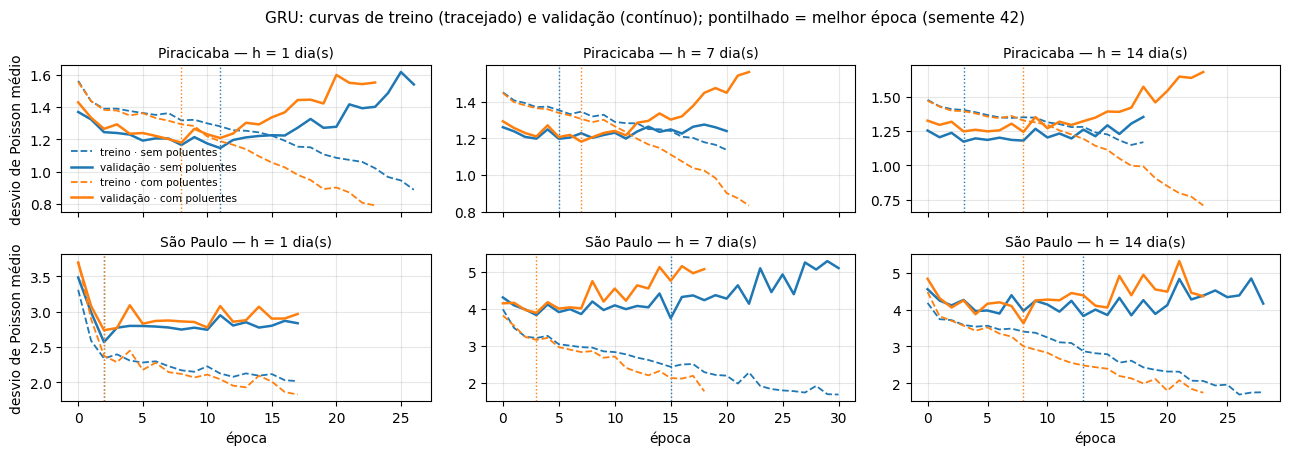

In [ ]:
# ---------------- Figura: curvas de treino e validação do GRU (semente 42) ----------------
CORES = {'sem': 'tab:blue', 'com': 'tab:orange'}
fig, axes = plt.subplots(len(MUNICIPIOS), len(HORIZONTES), figsize=(13, 4.6), sharex='col', squeeze=False)
for i, m in enumerate(MUNICIPIOS):
    for j, h in enumerate(HORIZONTES):
        ax = axes[i, j]
        for versao in ('sem', 'com'):
            htr, hva, melhor = GRU_CURVAS[(m, h, versao, SEMENTES_GRU[0])]
            ax.plot(htr, color=CORES[versao], ls='--', lw=1.3, label=f'treino · {versao} poluentes')
            ax.plot(hva, color=CORES[versao], ls='-', lw=1.8, label=f'validação · {versao} poluentes')
            ax.axvline(melhor - 1, color=CORES[versao], ls=':', lw=1)
        ax.set_title(f'{m} — h = {h} dia(s)', fontsize=10)
        ax.grid(alpha=.3)
        if j == 0:
            ax.set_ylabel('desvio de Poisson médio')
        if i == len(MUNICIPIOS) - 1:
            ax.set_xlabel('época')
axes[0, 0].legend(fontsize=7.5, frameon=False)
fig.suptitle(f'GRU: curvas de treino (tracejado) e validação (contínuo); pontilhado = melhor época (semente {SEMENTES_GRU[0]})', fontsize=11)
fig.tight_layout()
fig.savefig('fig_final_curvas_gru.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Avaliação final no teste (2019): única consulta
**A partir daqui o teste é lido, uma única vez.** Nada muda depois de olhar o resultado: os modelos (pesos do Poisson, estados do GRU, fatores sazonais), os hiperparâmetros, os atributos e o critério de empate foram congelados na validação. Os modelos foram treinados só com 2014–2017 (a validação serviu à parada antecipada e à escolha do `alpha`); não há retreino com a validação. Os dados passam a ir até 31/12/2019, e o notebook confirma que isso não altera nenhum valor até 2018.

In [ ]:
# ======================= AVALIAÇÃO FINAL NO TESTE (2019) — ÚNICA CONSULTA =======================
TESTE = {m: preparar_municipio(m, FIM_TESTE) for m in MUNICIPIOS}      # agora os dados vão até 31/12/2019

# Incluir 2019 não pode mudar nada até 2018: todo parâmetro estimado vem só do treino.
for m in MUNICIPIOS:
    a, b = DEV[m], TESTE[m]
    assert a['y'].equals(b['y'].loc[:FIM_VAL]) and a['pol'] == b['pol'] and a['met'] == b['met']
    assert np.allclose(a['z'].to_numpy(), b['z'].loc[:FIM_VAL].to_numpy()), 'a inclusão do teste alterou o pré-processamento'

res_te_linhas = []
for m, d in TESTE.items():
    y, z, pol, met = d['y'], d['z'], d['pol'], d['met']
    saz = CONG[(m, 'saz')]
    for h in HORIZONTES:
        F = montar_features(y, z, pol, met, h)
        checar_sem_vazamento(F, y, z, h, pol, met, ultimo_dia=FIM_TESTE)
        te = F.loc[INI_TESTE:FIM_TESTE]
        assert len(te) == 365 and te.index.min() == pd.Timestamp(INI_TESTE) and te.index.max() == pd.Timestamp(FIM_TESTE)
        yte = te['y'].to_numpy()
        base = dict(municipio=m, horizonte=h, n_treino=len(LINHAS[(m, h)][0]), n_alvo=len(te), media_alvo=float(yte.mean()))

        p = saz.predict(te.index)
        res_te_linhas.append(dict(base, modelo=NOME_SAZ, semente=np.nan, MAE=mae(yte, p), MAE_mediana=mae_mediana(yte, p)))
        for nome in (NOME_P_SEM, NOME_P_COM):                                   # Poisson: pesos e padronização congelados
            cfg = CONG[(m, h, nome)]
            mu = np.exp(np.clip(padronizar(te, cfg['cols'], cfg['estat']) @ cfg['w'] + cfg['b'], -20, 20))
            res_te_linhas.append(dict(base, modelo=nome, semente=np.nan, MAE=mae(yte, mu),
                                      MAE_mediana=mae_mediana(yte, mu), alpha=cfg['alpha']))
        for versao, nome in [('sem', NOME_G_SEM), ('com', NOME_G_COM)]:         # GRU: estados congelados, uma linha por semente
            X, cal, ya = amostras_gru(d, ESC[m], versao, h, te.index)
            for seed in SEMENTES_GRU:
                mu = prever_gru(GRU_ESTADOS[(m, h, versao, seed)], X, cal)
                res_te_linhas.append(dict(base, modelo=nome, semente=seed, MAE=mae(ya, mu), MAE_mediana=mae_mediana(ya, mu)))

res_te = preparar_resultados(res_te_linhas)
ag_te = agregar(res_te)
print(f'Teste avaliado: {len(res_te)} linhas ({len(TESTE)} municípios × {len(HORIZONTES)} horizontes; N = 365 dias em cada um).')
print('\nMAE de teste (média ± desvio-padrão entre sementes; Poisson e média sazonal sem desvio):')
display(tabela_mm(ag_te))
print('\nMAE relativo no teste (% da média diária de internações):')
display(tabela_rel(ag_te))

Teste avaliado: 54 linhas (2 municípios × 3 horizontes; N = 365 dias em cada um).

MAE de teste (média ± desvio-padrão entre sementes; Poisson e média sazonal sem desvio):


h = 1 d       h = 7 d      h = 14 d
municipio  modelo                                                         
Piracicaba Média sazonal                  2.06          2.06          2.06
           Poisson sem poluentes          1.90          1.91          1.96
           Poisson com poluentes          1.88          1.91          1.94
           GRU sem poluentes       1.94 ± 0.03   1.92 ± 0.02   1.95 ± 0.03
           GRU com poluentes       1.93 ± 0.02   1.92 ± 0.02   1.94 ± 0.01
São Paulo  Média sazonal                 19.61         19.61         19.61
           Poisson sem poluentes         14.68         17.83         19.18
           Poisson com poluentes         14.73         17.74         19.88
           GRU sem poluentes      14.81 ± 0.35  17.91 ± 0.51  18.15 ± 0.41
           GRU com poluentes      14.80 ± 0.18  18.21 ± 0.54  18.88 ± 0.75


MAE relativo no teste (% da média diária de internações):


h = 1 d h = 7 d h = 14 d
municipio  modelo                                        
Piracicaba Média sazonal            40.6    40.6     40.6
           Poisson sem poluentes    37.4    37.5     38.5
           Poisson com poluentes    37.0    37.5     38.3
           GRU sem poluentes        38.2    37.8     38.4
           GRU com poluentes        37.9    37.8     38.3
São Paulo  Média sazonal            13.7    13.7     13.7
           Poisson sem poluentes    10.2    12.4     13.4
           Poisson com poluentes    10.3    12.4     13.9
           GRU sem poluentes        10.3    12.5     12.7
           GRU com poluentes        10.3    12.7     13.2

### Critério de empate (proposta, seção 7)
Aplicado **no horizonte de 1 dia**, em cada município; os horizontes de 7 e 14 dias são descritivos. Interpretação operacional (fixada antes de ver o teste):
- **Os poluentes ajudam** em um município se `MAE_médio(GRU sem) − MAE_médio(GRU com) > 2 × dp`, em que `dp` é o **maior** dos dois desvios-padrão entre sementes (`ddof = 1`), a escolha mais conservadora. Vale se isso ocorrer na **maioria** dos municípios; com 2 municípios, a maioria exige **os dois**. Caso contrário, a resposta é *"os poluentes não melhoram a previsão"*.
- **A rede se justifica** em um município se `MAE(melhor Poisson) − MAE_médio(GRU sem) > 2 × dp(GRU sem)`. O "melhor Poisson" é o de menor MAE de teste entre as versões sem e com poluentes (o comparador mais exigente). Vale na maioria dos municípios; caso contrário, a resposta é *"a rede não se justifica"*.
Em ambos os casos o trabalho está completo.

In [ ]:
# ---------------- Critério de empate: horizonte de 1 dia ----------------
def maes(res, m, h, nome):
    return res[(res.municipio == m) & (res.horizonte == h) & (res.modelo == nome)]['MAE'].to_numpy()

def avaliar_criterio(res, h):
    linhas = []
    for m in MUNICIPIOS:
        sem, com = maes(res, m, h, NOME_G_SEM), maes(res, m, h, NOME_G_COM)
        dp_sem, dp_com = float(sem.std(ddof=1)), float(com.std(ddof=1))
        dp_ref = max(dp_sem, dp_com)
        ganho_pol = float(sem.mean() - com.mean())                      # > 0: com poluentes é melhor
        p_sem, p_com = float(maes(res, m, h, NOME_P_SEM)[0]), float(maes(res, m, h, NOME_P_COM)[0])
        nome_p, mae_p = (NOME_P_SEM, p_sem) if p_sem <= p_com else (NOME_P_COM, p_com)
        ganho_rede = mae_p - float(sem.mean())                          # > 0: GRU sem poluentes é melhor que o melhor Poisson
        linhas.append(dict(municipio=m, horizonte=h, MAE_GRU_sem=sem.mean(), dp_GRU_sem=dp_sem,
                           MAE_GRU_com=com.mean(), dp_GRU_com=dp_com, ganho_poluentes=ganho_pol,
                           limiar_2dp=LIMIAR_DP * dp_ref, poluentes_ajudam=bool(ganho_pol > LIMIAR_DP * dp_ref),
                           melhor_poisson=nome_p, MAE_melhor_poisson=mae_p, ganho_rede=ganho_rede,
                           limiar_rede_2dp=LIMIAR_DP * dp_sem, rede_se_justifica=bool(ganho_rede > LIMIAR_DP * dp_sem)))
    return pd.DataFrame(linhas)

crit = avaliar_criterio(res_te, h=1)
display(crit.round(3).T)

maioria = len(MUNICIPIOS) // 2 + 1
n_pol, n_rede = int(crit['poluentes_ajudam'].sum()), int(crit['rede_se_justifica'].sum())
print(f'\n1) Poluentes: ajudam em {n_pol} de {len(MUNICIPIOS)} municípios (a maioria exige {maioria}).')
print('   RESPOSTA:', 'os poluentes melhoram a previsão.' if n_pol >= maioria else 'os poluentes não melhoram a previsão.')
print(f'2) Rede: GRU sem poluentes supera o melhor Poisson em {n_rede} de {len(MUNICIPIOS)} municípios (a maioria exige {maioria}).')
print('   RESPOSTA:', 'a rede se justifica.' if n_rede >= maioria else 'a rede não se justifica.')

# horizontes de 7 e 14 dias: apenas descritivos
desc = pd.concat([avaliar_criterio(res_te, h)[['municipio', 'horizonte', 'ganho_poluentes', 'limiar_2dp', 'poluentes_ajudam']]
                  for h in HORIZONTES], ignore_index=True)
print('\nGanho dos poluentes no GRU (MAE sem − MAE com; positivo = com poluentes melhor), todos os horizontes (7 e 14 dias: descritivo):')
display(desc.round(3))

,0,1
municipio,Piracicaba,São Paulo
horizonte,1,1
MAE_GRU_sem,1.939,14.812
dp_GRU_sem,0.029,0.347
MAE_GRU_com,1.927,14.797
dp_GRU_com,0.022,0.184
ganho_poluentes,0.013,0.015
limiar_2dp,0.057,0.693
poluentes_ajudam,False,False
melhor_poisson,Poisson com poluentes,Poisson sem poluentes



1) Poluentes: ajudam em 0 de 2 municípios (a maioria exige 2).
   RESPOSTA: os poluentes não melhoram a previsão.
2) Rede: GRU sem poluentes supera o melhor Poisson em 0 de 2 municípios (a maioria exige 2).
   RESPOSTA: a rede não se justifica.

Ganho dos poluentes no GRU (MAE sem − MAE com; positivo = com poluentes melhor), todos os horizontes (7 e 14 dias: descritivo):


,municipio,horizonte,ganho_poluentes,limiar_2dp,poluentes_ajudam
0,Piracicaba,1,0.013,0.057,False
1,São Paulo,1,0.015,0.693,False
2,Piracicaba,7,-0.002,0.040,False
3,São Paulo,7,-0.299,1.077,False
4,Piracicaba,14,0.007,0.051,False
5,São Paulo,14,-0.730,1.494,False


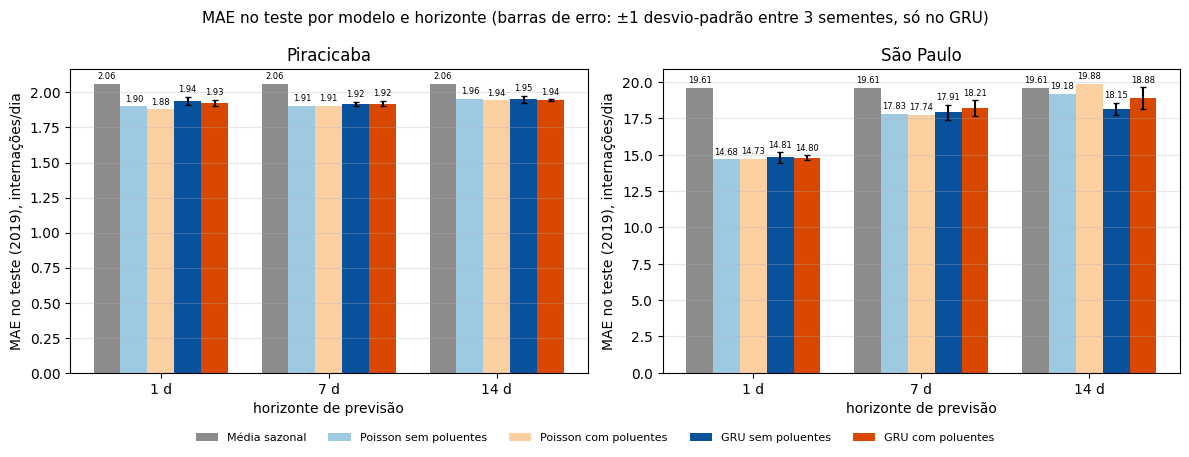

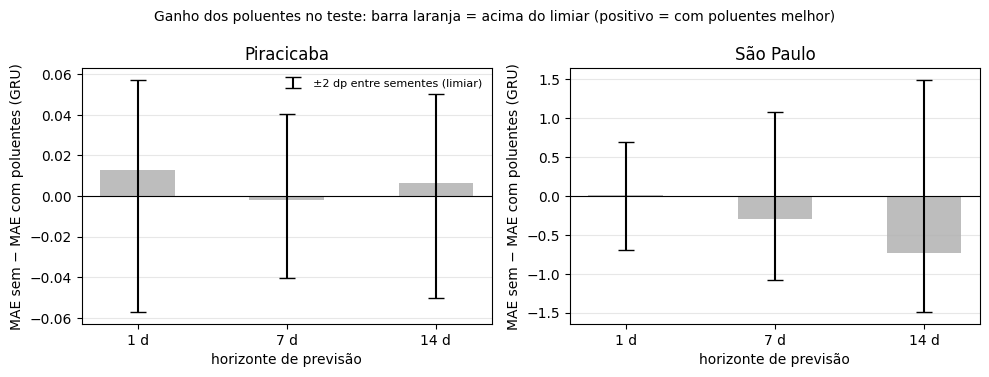

In [ ]:
# ---------------- Figuras do artigo (teste) ----------------
CORES_MOD = {NOME_SAZ: '#8c8c8c', NOME_P_SEM: '#9ecae1', NOME_P_COM: '#fdd0a2', NOME_G_SEM: '#08519c', NOME_G_COM: '#d94801'}

# Figura principal: MAE de teste por horizonte e modelo (barra de erro = ±1 dp entre sementes, só no GRU)
fig, axes = plt.subplots(1, len(MUNICIPIOS), figsize=(12, 4.3))
largura = 0.16
for ax, m in zip(np.atleast_1d(axes), MUNICIPIOS):
    for k, nome in enumerate(ORDEM_MODELOS):
        sub = ag_te[(ag_te.municipio == m) & (ag_te.modelo == nome)].sort_values('horizonte')
        pos = np.arange(len(HORIZONTES)) + (k - 2) * largura
        erro = sub['MAE_dp'].to_numpy() if nome in (NOME_G_SEM, NOME_G_COM) else None
        barras = ax.bar(pos, sub['MAE_media'], largura, yerr=erro, capsize=2, color=CORES_MOD[nome], label=nome, ecolor='black')
        ax.bar_label(barras, fmt='%.2f', fontsize=6, padding=2)
    ax.set_xticks(np.arange(len(HORIZONTES)))
    ax.set_xticklabels([f'{h} d' for h in HORIZONTES])
    ax.set_title(m); ax.set_xlabel('horizonte de previsão'); ax.set_ylabel('MAE no teste (2019), internações/dia')
    ax.grid(axis='y', alpha=.3)
h_, l_ = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(h_, l_, loc='lower center', ncol=5, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.05))
fig.suptitle('MAE no teste por modelo e horizonte (barras de erro: ±1 desvio-padrão entre 3 sementes, só no GRU)', fontsize=11)
fig.tight_layout()
fig.savefig('fig_final_mae_teste.png', dpi=200, bbox_inches='tight')
plt.show()

# Figura 2: ganho dos poluentes no GRU (MAE sem − MAE com) contra o limiar de 2 desvios-padrão
fig, axes = plt.subplots(1, len(MUNICIPIOS), figsize=(10, 3.8))
for ax, m in zip(np.atleast_1d(axes), MUNICIPIOS):
    sub = desc[desc.municipio == m].sort_values('horizonte')
    x = np.arange(len(sub))
    ax.bar(x, sub['ganho_poluentes'], 0.5, color=['#d94801' if g > t else '#bdbdbd' for g, t in zip(sub['ganho_poluentes'], sub['limiar_2dp'])])
    ax.errorbar(x, np.zeros(len(sub)), yerr=sub['limiar_2dp'], fmt='none', ecolor='black', capsize=6, lw=1.5,
                label=f'±{LIMIAR_DP:g} dp entre sementes (limiar)')
    ax.axhline(0, color='black', lw=.8)
    ax.set_xticks(x); ax.set_xticklabels([f'{h} d' for h in sub['horizonte']])
    ax.set_title(m); ax.set_xlabel('horizonte de previsão'); ax.set_ylabel('MAE sem − MAE com poluentes (GRU)')
    ax.grid(axis='y', alpha=.3)
np.atleast_1d(axes)[0].legend(fontsize=8, frameon=False)
fig.suptitle('Ganho dos poluentes no teste: barra laranja = acima do limiar (positivo = com poluentes melhor)', fontsize=10)
fig.tight_layout()
fig.savefig('fig_final_ganho_poluentes.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# ---------------- Tabelas e arquivos de saída ----------------
final = ag_val[['municipio', 'horizonte', 'modelo', 'MAE_media', 'MAE_dp', 'MAE_rel_media']].merge(
    ag_te[['municipio', 'horizonte', 'modelo', 'MAE_media', 'MAE_dp', 'MAE_rel_media']],
    on=['municipio', 'horizonte', 'modelo'], suffixes=('_val', '_teste'))
res_val.to_csv('resultados_validacao_por_execucao.csv', index=False)
res_te.to_csv('resultados_teste_por_execucao.csv', index=False)
final.to_csv('resultados_finais_agregados.csv', index=False)
crit.to_csv('criterio_de_empate_h1.csv', index=False)

gru = ag_val[ag_val.modelo.isin([NOME_G_SEM, NOME_G_COM])]
print('GRU: épocas médias até parar e tempo médio por treino (CPU), por município e versão:')
display(gru.groupby(['municipio', 'modelo'], observed=True).agg(epocas_medias=('epocas_medias', 'mean'),
                                                                 tempo_medio_s=('tempo_medio_s', 'mean')).round(1))
print('\nTabela para o artigo (teste; média ± desvio-padrão entre sementes):')
display(tabela_mm(ag_te))

GRU: épocas médias até parar e tempo médio por treino (CPU), por município e versão:


epocas_medias  tempo_medio_s
municipio  modelo                                         
Piracicaba GRU sem poluentes           23.0           10.4
           GRU com poluentes           23.2           12.5
São Paulo  GRU sem poluentes           26.6           11.2
           GRU com poluentes           20.1            8.5


Tabela para o artigo (teste; média ± desvio-padrão entre sementes):


h = 1 d       h = 7 d      h = 14 d
municipio  modelo                                                         
Piracicaba Média sazonal                  2.06          2.06          2.06
           Poisson sem poluentes          1.90          1.91          1.96
           Poisson com poluentes          1.88          1.91          1.94
           GRU sem poluentes       1.94 ± 0.03   1.92 ± 0.02   1.95 ± 0.03
           GRU com poluentes       1.93 ± 0.02   1.92 ± 0.02   1.94 ± 0.01
São Paulo  Média sazonal                 19.61         19.61         19.61
           Poisson sem poluentes         14.68         17.83         19.18
           Poisson com poluentes         14.73         17.74         19.88
           GRU sem poluentes      14.81 ± 0.35  17.91 ± 0.51  18.15 ± 0.41
           GRU com poluentes      14.80 ± 0.18  18.21 ± 0.54  18.88 ± 0.75

In [ ]:
# ---------------- Tempo de execução e resumo da reprodutibilidade ----------------
t_total = time.perf_counter() - T0
n_gru = len(res_val[res_val.modelo.isin([NOME_G_SEM, NOME_G_COM])])
print(f'Tempo total de execução (da leitura dos dados até aqui): {t_total / 60:.1f} min ({t_total:.0f} s) — {AMBIENTE}')
print(f'Treinos de GRU: {n_gru} ({len(MUNICIPIOS)} municípios × {len(HORIZONTES)} horizontes × 2 versões × {len(SEMENTES_GRU)} sementes) | sementes {SEMENTES_GRU}')
print(f'Hiperparâmetros do GRU: janela {JANELA}, hidden {HIDDEN}, dropout {DROPOUT}, lr {GRU_LR}, weight decay {GRU_WD}, '
      f'lote {BATCH}, até {GRU_MAX_EPOCAS} épocas, paciência {GRU_PACIENCIA}')
print('Arquivos gerados: fig_final_mae_teste.png (figura principal), fig_final_ganho_poluentes.png, fig_final_curvas_gru.png,')
print('                  resultados_finais_agregados.csv, resultados_validacao_por_execucao.csv, resultados_teste_por_execucao.csv,')
print('                  criterio_de_empate_h1.csv, checkpoints_gru/')
if NO_COLAB:
    print('No Colab, baixe esses arquivos (painel Arquivos) ou copie-os para o Drive: a sessão é descartável.')

Tempo total de execução (da leitura dos dados até aqui): 6.8 min (408 s) — Google Colab (CPU)
Treinos de GRU: 36 (2 municípios × 3 horizontes × 2 versões × 3 sementes) | sementes [42, 43, 44]
Hiperparâmetros do GRU: janela 28, hidden 64, dropout 0.1, lr 0.003, weight decay 0.0001, lote 64, até 150 épocas, paciência 15
Arquivos gerados: fig_final_mae_teste.png (figura principal), fig_final_ganho_poluentes.png, fig_final_curvas_gru.png,
                  resultados_finais_agregados.csv, resultados_validacao_por_execucao.csv, resultados_teste_por_execucao.csv,
                  criterio_de_empate_h1.csv, checkpoints_gru/
No Colab, baixe esses arquivos (painel Arquivos) ou copie-os para o Drive: a sessão é descartável.


## 7. Reprodutibilidade
- **Figura principal:** `fig_final_mae_teste.png`, gerada ao executar o notebook inteiro: no Colab, `Ambiente de execução → Executar tudo`; fora do Colab, `jupyter nbconvert --to notebook --execute FINAL_problemas_respiratorios.ipynb`.
- **Dados:** `dados_t2.zip` do repositório, baixado sozinho se não estiver no ambiente. A coleta a partir das fontes originais está em `extracao_dados_brutos/` e no README do repositório.
- **Ambiente e sementes:** o ambiente e as versões das bibliotecas saem na primeira célula; as sementes do GRU estão em `SEMENTES_GRU` (42, 43 e 44) e o número de treinos, na última célula de código. A média sazonal e o Poisson são determinísticos; o GRU pode variar um pouco entre máquinas e versões de biblioteca.